In [45]:
# 그래프 관련
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np

# 머신러닝 관련
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.metrics import mean_absolute_error 
from sklearn.linear_model import LogisticRegression
from scipy.special import expit

In [46]:
#[ 도미 ]
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0,
33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0,
610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]

#[ 빙어 ]
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [47]:
length = bream_length + smelt_length
weight = bream_weight + smelt_weight

data = np.column_stack((length,weight))
label = [1]*35 + [0]*14     #도미 35마리, 빙어 14마리

In [48]:
# 학습데이터/시험데이터 분리
train_data,test_data,train_label,test_label = train_test_split(data,label, stratify=label,test_size=0.2)

In [49]:
# 정규화
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)


In [53]:
lr = LogisticRegression()
lr.fit(train_scaled, train_label)
print(f"훈련 정확도: {lr.score(train_scaled, train_label)*100:.2f}%")
print(f"테스트 정확도: {lr.score(test_scaled, test_label)*100:.2f}%")


훈련 정확도: 100.00%
테스트 정확도: 100.00%


In [55]:
# LogisticRegression 활용
# 길이 21, 무게 90 예측
# 길이 25, 무게 150 예측

input1 = input('생선의 길이,무게(예:21,90)')
#input2 = input2.split(',')
# new_fish = list(map(float,input2))
new_fish = [[float(x) for x in input1.split(',')]]

# StandardScaler로 동일하게 정규화
new_fish_scaled = ss.transform(new_fish)

# 예측 및 확률 계산
pred = lr.predict(new_fish_scaled)[0]
proba = lr.predict_proba(new_fish_scaled)[0]

species = "도미(1)" if pred == 1 else "빙어(0)"
confidence = np.max(proba) * 100

print(f'\n 예측 결과: {species} / 확률: {confidence:.2f}%')


 예측 결과: 도미(1) / 확률: 67.53%


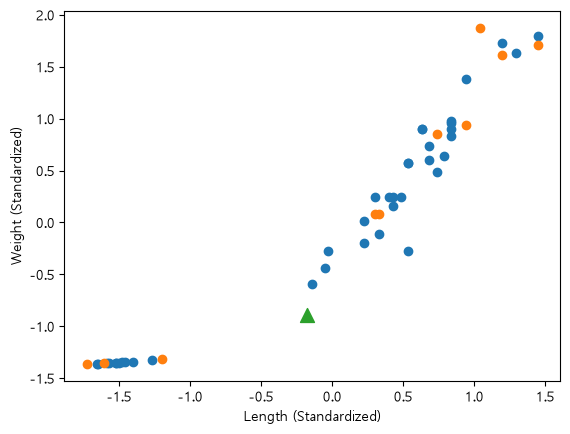

In [ ]:
plt.scatter(train_scaled[:,0], train_scaled[:,1], label='Train data')
plt.scatter(test_scaled[:,0], test_scaled[:,1], label='Test data')
plt.scatter(new_fish_scaled[0, 0], new_fish_scaled[0, 1], marker='^', s=100, label='New fish')
plt.xlabel('Length (Standardized)')
plt.ylabel('Weight (Standardized)')
plt.show()